In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import shutil
from IPython.display import Audio
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
DATASET_PATH = "/content/drive/MyDrive/ASR_project/MONO_Lingual/RAVDESS/AudioFiles_AUG"
DATASET_PATH

'/content/drive/MyDrive/ASR_project/MONO_Lingual/RAVDESS/AudioFiles_AUG'

In [ ]:
import os

paths = []
labels = []

# RAVDESS emotion mapping (standard)
emotion_map = {
    '01': 0,  # neutral
    '02': 1,  # calm
    '03': 2,  # happy
    '04': 3,  # sad
    '05': 4,  # angry
    '06': 5,  # fearful
    '07': 6,  # disgust
    '08': 7   # surprised
}

for dirname, _, filenames in os.walk(DATASET_PATH):
    for filename in filenames:

        # consider only wav files
        if not filename.endswith('.wav'):
            continue

        # full path
        file_path = os.path.join(dirname, filename)
        paths.append(file_path)

        # remove augmentation suffix if present
        # example: 03-01-08-02-01-02-17_gain.wav → 03-01-08-02-01-02-17.wav
        base_name = filename.split('_')[0]

        # extract emotion code
        # MM-VC-EE-II-SS-RR-AA.wav → EE is index 2
        emotion_code = base_name.split('-')[2]

        # map to numeric label
        label = emotion_map[emotion_code]
        labels.append(label)

print('Dataset is Loaded')

Dataset is Loaded


In [ ]:
## Create a dataframe
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels
df.head()
df

,speech,label
0,/content/drive/MyDrive/ASR_project/MONO_Lingua...,4
1,/content/drive/MyDrive/ASR_project/MONO_Lingua...,5
2,/content/drive/MyDrive/ASR_project/MONO_Lingua...,3
3,/content/drive/MyDrive/ASR_project/MONO_Lingua...,5
4,/content/drive/MyDrive/ASR_project/MONO_Lingua...,1
...,...,...
5755,/content/drive/MyDrive/ASR_project/MONO_Lingua...,1
5756,/content/drive/MyDrive/ASR_project/MONO_Lingua...,4
5757,/content/drive/MyDrive/ASR_project/MONO_Lingua...,7
5758,/content/drive/MyDrive/ASR_project/MONO_Lingua...,5


5

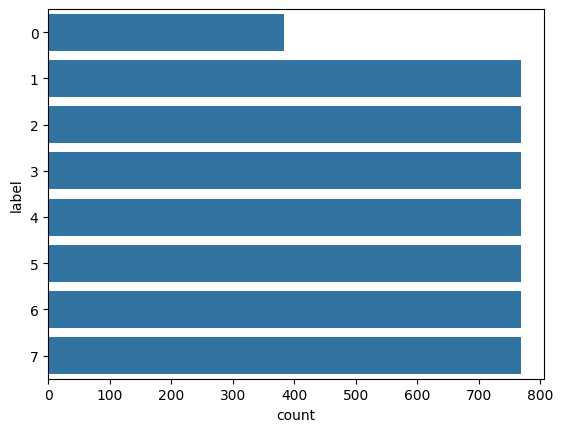

In [ ]:
#Ploting label vs no of data for each emotion
import seaborn as sns
sns.countplot(data=df, y='label')
label

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

# mfcc extraction

def extract_mfcc(file_path, n_mfcc=40, max_len=174):
    signal, sr = librosa.load(file_path, sr=22050)

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=n_mfcc
    )

    mfcc = mfcc.T  # (time, n_mfcc)

    # padding / truncation
    if mfcc.shape[0] < max_len:
        pad_width = max_len - mfcc.shape[0]
        mfcc = np.pad(mfcc, ((0, pad_width), (0, 0)), mode='constant')
    else:
        mfcc = mfcc[:max_len, :]

    return mfcc


In [ ]:
# weighted mfcc extraction

def extract_weighted_mfcc(file_path, n_mfcc=40, max_len=174):
    mfcc = extract_mfcc(file_path, n_mfcc, max_len)

    # weight coefficients (higher MFCCs slightly down-weighted)
    weights = np.linspace(1.0, 0.5, n_mfcc)

    weighted_mfcc = mfcc * weights

    return weighted_mfcc



In [ ]:
# mfcc and weighted mfcc storage

X_mfcc = []
X_wmfcc = []
y = []

for idx, row in df.iterrows():
    file_path = row['speech']
    label = row['label']

    mfcc = extract_mfcc(file_path)
    wmfcc = extract_weighted_mfcc(file_path)

    X_mfcc.append(mfcc)
    X_wmfcc.append(wmfcc)
    y.append(label)

X_mfcc = np.array(X_mfcc)
X_wmfcc = np.array(X_wmfcc)
y = np.array(y)


In [ ]:
# mfcc + SMOTE

samples, time_steps, n_mfcc = X_mfcc.shape

X_mfcc_flat = X_mfcc.reshape(samples, time_steps * n_mfcc)

smote = SMOTE(random_state=42)
X_mfcc_smote, y_smote = smote.fit_resample(X_mfcc_flat, y)

X_mfcc_smote = X_mfcc_smote.reshape(
    X_mfcc_smote.shape[0],
    time_steps,
    n_mfcc
)


In [ ]:
# weighted mfcc + SMOTE

samples, time_steps, n_mfcc = X_wmfcc.shape

X_wmfcc_flat = X_wmfcc.reshape(samples, time_steps * n_mfcc)

X_wmfcc_smote, y_smote = smote.fit_resample(X_wmfcc_flat, y)

X_wmfcc_smote = X_wmfcc_smote.reshape(
    X_wmfcc_smote.shape[0],
    time_steps,
    n_mfcc
)

In [ ]:
y_smote = np.array(y_smote)

SAVE_DIR = "/content/drive/MyDrive/Ravdess_features"
os.makedirs(SAVE_DIR, exist_ok=True)

np.save(
    os.path.join(SAVE_DIR, "y_smote.npy"),
    y_smote
)

In [ ]:
X_mfcc_smote = np.load("/content/drive/MyDrive/Ravdess_features/RAVDESS_mfcc_smote.npy")

In [ ]:
y_smote = np.load("/content/drive/MyDrive/Ravdess_features/RAVDESS_y_smote.npy")

In [ ]:
X_wmfcc_smote = np.load("/content/drive/MyDrive/Ravdess_features/RAVDESS_wmfcc_smote.npy")

In [ ]:
X_mfcc_smote.shape

(6144, 174, 40)

In [ ]:
y_smote.shape

(6144,)

In [ ]:
X_wmfcc_smote.shape

(6144, 174, 40)

In [ ]:
y_smote

array([4, 5, 2, ..., 0, 0, 0])

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, classification_report)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [ ]:
# Create LSTM Model

def create_lstm_model(input_shape, num_classes):
    """Create LSTM model"""
    model = Sequential([
        LSTM(128, input_shape=input_shape, return_sequences=True),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='rmsprop',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# Create Bi-LSTM Model

def create_bilstm_model(input_shape, num_classes):
    """Create Bi-LSTM model"""
    model = Sequential([
        Bidirectional(LSTM(128, return_sequences=True), input_shape=input_shape),
        Dropout(0.3),
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='rmsprop',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluate model on test set and print metrics

    Parameters:
    - model: trained model
    - X_test, y_test: test data
    - model_name: name of the model (for display)

    Returns:
    - test_metrics: dictionary with all metrics
    - y_pred: predictions
    """
    print(f"\n{'='*70}")
    print(f"{model_name} - Test Set Evaluation")
    print(f"{'='*70}")

    # Predict on test data
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)

    # Calculate test metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"\nTest Accuracy:  {accuracy:.4f}")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall:    {recall:.4f}")
    print(f"Test F1-Score:  {f1:.4f}")

    print(f"\nClassification Report:")
    print("-" * 70)
    print(classification_report(y_test, y_pred))

    # Plot confusion matrix
    # If y_test is one-hot encoded, convert to class labels
    if len(y_test.shape) > 1:
        y_true = np.argmax(y_test, axis=1)
    else:
        y_true = y_test

    # y_pred is already returned from evaluate_model()
    #   Ensure it is class labels
    if len(y_pred.shape) > 1:
        y_pred_labels = np.argmax(y_pred, axis=1)
    else:
        y_pred_labels = y_pred

    # Create class names dynamically
    num_classes = len(np.unique(y_true))
    class_names = [f"Class {i}" for i in range(num_classes)]

    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred_labels)

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

    test_metrics = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'confusion_matrix': cm
    }

    return test_metrics, y_pred

In [ ]:
# # Plot Confusion matrix function

# def plot_confusion_matrix(y_true, y_pred, title, class_names=None):
#     """Plot confusion matrix"""
#     cm = confusion_matrix(y_true, y_pred)

#     plt.figure(figsize=(8, 6))
#     sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#                 xticklabels=class_names, yticklabels=class_names)
#     plt.title(title)
#     plt.ylabel('True Label')
#     plt.xlabel('Predicted Label')
#     plt.tight_layout()
#     plt.show()

#     return cm


In [ ]:

from sklearn.metrics import confusion_matrix

In [ ]:
def train_with_kfold(X_train, y_train, X_test, y_test,
                     model_type='LSTM', n_splits=5):
    """
    Train model with Stratified K-Fold (ONE TRAINING ONLY)
    Uses K-fold on training data, evaluates on separate test set

    Parameters:
    - X_train, y_train: training data
    - X_test, y_test: test data (never used in training)
    - model_type: 'LSTM' or 'BiLSTM'
    - n_splits: number of folds

    Returns:
    - fold_results: fold-wise accuracy and loss for each fold
    - test_metrics: test set metrics using best fold model
    - best_model: model from best validation fold
    """
    num_classes = len(np.unique(y_train))
    input_shape = (X_train.shape[1], X_train.shape[2])

    # Convert labels to categorical
    y_train_cat = to_categorical(y_train, num_classes)
    y_test_cat = to_categorical(y_test, num_classes)

    # Initialize Stratified K-Fold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Store fold results
    fold_accuracies = []
    fold_losses = []
    fold_models = []

    print(f"\n{'='*70}")
    print(f"Training {model_type} Model with {n_splits}-Fold Cross-Validation")
    print(f"{'='*70}")

    # K-Fold Cross-Validation
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
        print(f"\n{'='*70}")
        print(f"Fold {fold}/{n_splits}")
        print(f"{'='*70}")

        # Split data
        X_fold_train, X_fold_val = X_train[train_idx], X_train[val_idx]
        y_fold_train, y_fold_val = y_train_cat[train_idx], y_train_cat[val_idx]

        # Create model
        if model_type == 'LSTM':
            model = create_lstm_model(input_shape, num_classes)
        else:  # BiLSTM
            model = create_bilstm_model(input_shape, num_classes)

        # Train model
        history = model.fit(
            X_fold_train, y_fold_train,
            validation_data=(X_fold_val, y_fold_val),
            epochs=50,
            batch_size=32,
            verbose=1
        )

        # Get final validation metrics
        val_loss = history.history['val_loss'][-1]
        val_accuracy = history.history['val_accuracy'][-1]

        fold_accuracies.append(val_accuracy)
        fold_losses.append(val_loss)
        fold_models.append(model)

        print(f"\nFold {fold} Final Results:")
        print(f"  Validation Accuracy: {val_accuracy:.4f}")
        print(f"  Validation Loss: {val_loss:.4f}")

    # Print fold-wise summary
    print(f"\n{'='*70}")
    print(f"{model_type} - Fold-wise Results Summary")
    print(f"{'='*70}")
    for i, (acc, loss) in enumerate(zip(fold_accuracies, fold_losses), 1):
        print(f"Fold {i}: Accuracy = {acc:.4f}, Loss = {loss:.4f}")
    print(f"\nMean Accuracy: {np.mean(fold_accuracies):.4f} (+/- {np.std(fold_accuracies):.4f})")
    print(f"Mean Loss: {np.mean(fold_losses):.4f} (+/- {np.std(fold_losses):.4f})")

    # Select best model (highest validation accuracy)
    best_fold_idx = np.argmax(fold_accuracies)
    best_model = fold_models[best_fold_idx]

    print(f"\n✓ Best model: Fold {best_fold_idx + 1} with accuracy {fold_accuracies[best_fold_idx]:.4f}")

    # Evaluate best model on test set using separate evaluate_model function
    test_metrics, y_pred = evaluate_model(best_model, X_test, y_test, model_type)

    # Store results
    fold_results = {
        'fold_accuracies': fold_accuracies,
        'fold_losses': fold_losses,
        'best_fold': best_fold_idx + 1,
        'mean_accuracy': np.mean(fold_accuracies),
        'std_accuracy': np.std(fold_accuracies),
        'mean_loss': np.mean(fold_losses),
        'std_loss': np.std(fold_losses)
    }

    return fold_results, test_metrics, best_model, y_pred


Train-Test Split:
Training samples: 4915 (80%)
Test samples: 1229 (20%)
Input shape: (174, 40)

Training LSTM Model with 5-Fold Cross-Validation

Fold 1/5
Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.2228 - loss: 1.9577 - val_accuracy: 0.3611 - val_loss: 1.6552
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3538 - loss: 1.6926 - val_accuracy: 0.4395 - val_loss: 1.5478
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4078 - loss: 1.5756 - val_accuracy: 0.4476 - val_loss: 1.4585
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.4671 - loss: 1.4600 - val_accuracy: 0.4822 - val_loss: 1.3999
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5136 - loss: 1.3284 - val_accuracy: 0.4710 - val_loss: 1.3867
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5349 - loss: 1.2952 - val_accuracy: 0.5392 - val_loss: 1.2331
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.559

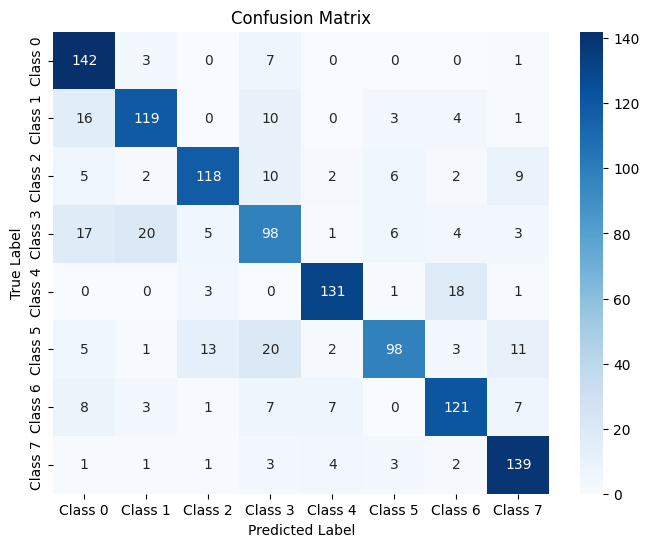

In [ ]:
# Split into 80% train and 20% train

X_train, X_test, y_train, y_test = train_test_split(
        X_mfcc_smote, y_smote,
        test_size=0.2,
        random_state=42,
        stratify=y_smote
)

print(f"\nTrain-Test Split:")
print(f"Training samples: {X_train.shape[0]} (80%)")
print(f"Test samples: {X_test.shape[0]} (20%)")
print(f"Input shape: {X_train.shape[1:]}")

# Initialize results dictionary
results = {}

# ===================== Train LSTM Model =====================
lstm_fold_results, lstm_test_metrics, lstm_model, lstm_pred = train_with_kfold(
    X_train, y_train, X_test, y_test,
    model_type='LSTM',
    n_splits=5
)

# Store LSTM results
results['LSTM'] = {
    'fold_accuracies': lstm_fold_results['fold_accuracies'],
    'fold_losses': lstm_fold_results['fold_losses'],
    'best_fold': lstm_fold_results['best_fold'],
    'mean_cv_accuracy': lstm_fold_results['mean_accuracy'],
    'std_cv_accuracy': lstm_fold_results['std_accuracy'],
    'mean_cv_loss': lstm_fold_results['mean_loss'],
    'std_cv_loss': lstm_fold_results['std_loss'],
    'test_accuracy': lstm_test_metrics['accuracy'],
    'test_precision': lstm_test_metrics['precision'],
    'test_recall': lstm_test_metrics['recall'],
    'test_f1_score': lstm_test_metrics['f1_score'],
    'confusion_matrix': lstm_test_metrics['confusion_matrix']
}


Training BiLSTM Model with 5-Fold Cross-Validation

Fold 1/5
Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.2128 - loss: 1.9710 - val_accuracy: 0.3672 - val_loss: 1.5984
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.3689 - loss: 1.6599 - val_accuracy: 0.4079 - val_loss: 1.4933
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.4158 - loss: 1.5452 - val_accuracy: 0.4822 - val_loss: 1.3855
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.4692 - loss: 1.4187 - val_accuracy: 0.4659 - val_loss: 1.3747
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.5045 - loss: 1.3431 - val_accuracy: 0.5412 - val_loss: 1.2393
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.5546 - loss: 1.2199 - val_accuracy: 0.5443 - val_loss: 1.2172
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.5871 - loss: 1.1277 - val_accuracy: 0.5829 - val_loss: 1.1632
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━

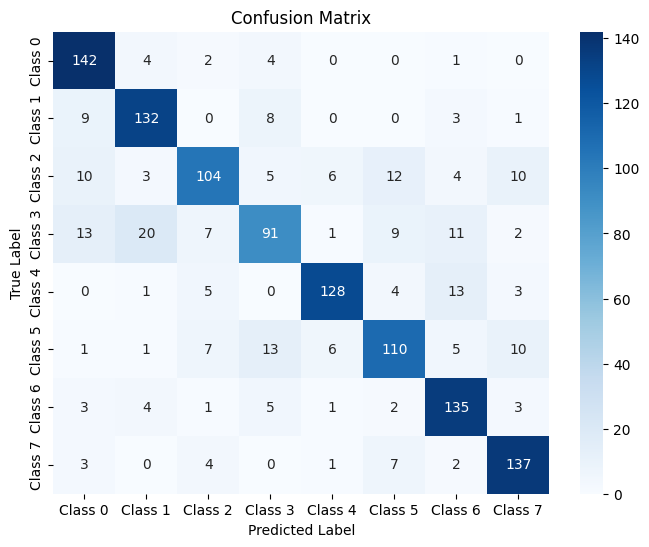

In [ ]:
bilstm_fold_results, bilstm_test_metrics, bilstm_model, bilstm_pred = train_with_kfold(
        X_train, y_train, X_test, y_test,
        model_type='BiLSTM',
        n_splits=5
)

    # Store Bi-LSTM results
results['BiLSTM'] = {
    'fold_accuracies': bilstm_fold_results['fold_accuracies'],
    'fold_losses': bilstm_fold_results['fold_losses'],
    'best_fold': bilstm_fold_results['best_fold'],
    'mean_cv_accuracy': bilstm_fold_results['mean_accuracy'],
    'std_cv_accuracy': bilstm_fold_results['std_accuracy'],
    'mean_cv_loss': bilstm_fold_results['mean_loss'],
    'std_cv_loss': bilstm_fold_results['std_loss'],
    'test_accuracy': bilstm_test_metrics['accuracy'],
    'test_precision': bilstm_test_metrics['precision'],
    'test_recall': bilstm_test_metrics['recall'],
    'test_f1_score': bilstm_test_metrics['f1_score'],
    'confusion_matrix': bilstm_test_metrics['confusion_matrix']
}


Train-Test Split:
Training samples: 4915 (80%)
Test samples: 1229 (20%)
Input shape: (174, 40)

Training LSTM Model with 5-Fold Cross-Validation

Fold 1/5
Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.2040 - loss: 1.9923 - val_accuracy: 0.3459 - val_loss: 1.6904
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3216 - loss: 1.7593 - val_accuracy: 0.3886 - val_loss: 1.5625
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.3603 - loss: 1.6462 - val_accuracy: 0.4151 - val_loss: 1.4939
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4196 - loss: 1.5451 - val_accuracy: 0.4364 - val_loss: 1.4841
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.4673 - loss: 1.4573 - val_accuracy: 0.4842 - val_loss: 1.3530
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5158 - loss: 1.3609 - val_accuracy: 0.5117 - val_loss: 1.2975
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.540

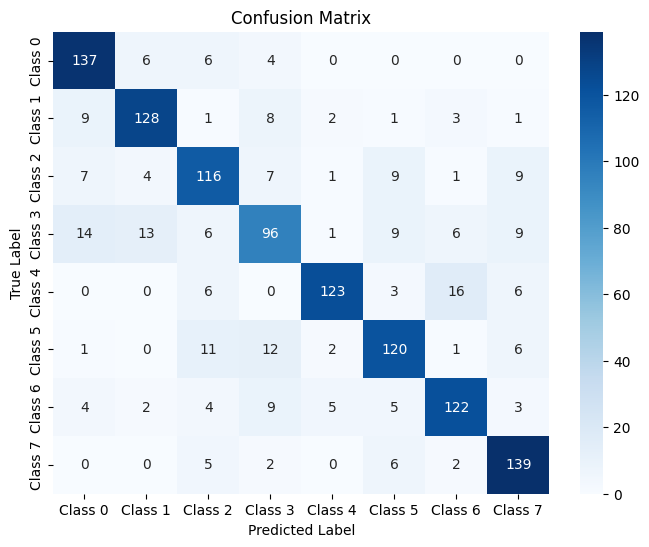

In [ ]:
# Split into 80% train and 20% train

X_train, X_test, y_train, y_test = train_test_split(
        X_wmfcc_smote, y_smote,
        test_size=0.2,
        random_state=42,
        stratify=y_smote
)

print(f"\nTrain-Test Split:")
print(f"Training samples: {X_train.shape[0]} (80%)")
print(f"Test samples: {X_test.shape[0]} (20%)")
print(f"Input shape: {X_train.shape[1:]}")


# ===================== Train LSTM Model =====================
lstm_fold_results, lstm_test_metrics, lstm_model, lstm_pred = train_with_kfold(
    X_train, y_train, X_test, y_test,
    model_type='LSTM',
    n_splits=5
)

# Store LSTM results
results['LSTM-WMFCC'] = {
    'fold_accuracies': lstm_fold_results['fold_accuracies'],
    'fold_losses': lstm_fold_results['fold_losses'],
    'best_fold': lstm_fold_results['best_fold'],
    'mean_cv_accuracy': lstm_fold_results['mean_accuracy'],
    'std_cv_accuracy': lstm_fold_results['std_accuracy'],
    'mean_cv_loss': lstm_fold_results['mean_loss'],
    'std_cv_loss': lstm_fold_results['std_loss'],
    'test_accuracy': lstm_test_metrics['accuracy'],
    'test_precision': lstm_test_metrics['precision'],
    'test_recall': lstm_test_metrics['recall'],
    'test_f1_score': lstm_test_metrics['f1_score'],
    'confusion_matrix': lstm_test_metrics['confusion_matrix']
}


Training BiLSTM Model with 5-Fold Cross-Validation

Fold 1/5
Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.2189 - loss: 1.9770 - val_accuracy: 0.3601 - val_loss: 1.6252
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.3441 - loss: 1.6917 - val_accuracy: 0.4262 - val_loss: 1.4861
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.4039 - loss: 1.5648 - val_accuracy: 0.4517 - val_loss: 1.4139
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.4668 - loss: 1.4468 - val_accuracy: 0.4771 - val_loss: 1.4279
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.5021 - loss: 1.3385 - val_accuracy: 0.5117 - val_loss: 1.3197
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.5246 - loss: 1.2801 - val_accuracy: 0.5086 - val_loss: 1.3367
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.5515 - loss: 1.2209 - val_accuracy: 0.5565 - val_loss: 1.1471
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━

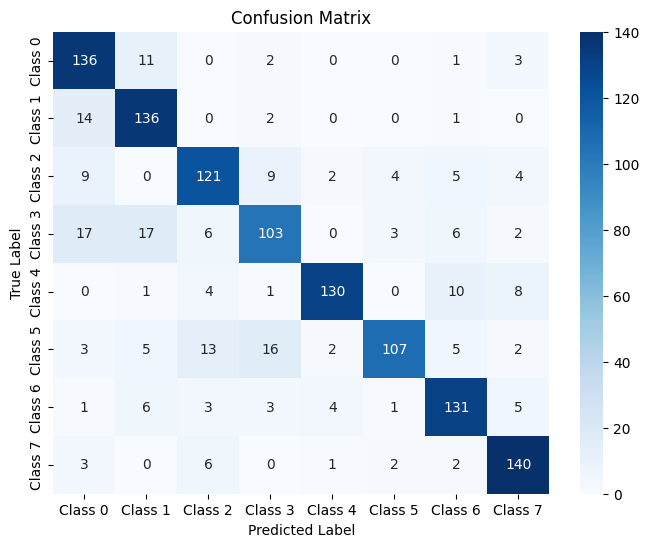

In [ ]:
bilstm_fold_results, bilstm_test_metrics, bilstm_model, bilstm_pred = train_with_kfold(
        X_train, y_train, X_test, y_test,
        model_type='BiLSTM',
        n_splits=5
)

    # Store Bi-LSTM results
results['BiLSTM-WMFCC'] = {
    'fold_accuracies': bilstm_fold_results['fold_accuracies'],
    'fold_losses': bilstm_fold_results['fold_losses'],
    'best_fold': bilstm_fold_results['best_fold'],
    'mean_cv_accuracy': bilstm_fold_results['mean_accuracy'],
    'std_cv_accuracy': bilstm_fold_results['std_accuracy'],
    'mean_cv_loss': bilstm_fold_results['mean_loss'],
    'std_cv_loss': bilstm_fold_results['std_loss'],
    'test_accuracy': bilstm_test_metrics['accuracy'],
    'test_precision': bilstm_test_metrics['precision'],
    'test_recall': bilstm_test_metrics['recall'],
    'test_f1_score': bilstm_test_metrics['f1_score'],
    'confusion_matrix': bilstm_test_metrics['confusion_matrix']
}

In [ ]:
display(accuracy_df)

,Model,Test Accuracy
0,LSTM (MFCC),0.786005
1,BiLSTM (MFCC),0.796583
2,LSTM (WMFCC),0.798210
3,BiLSTM (WMFCC),0.816924


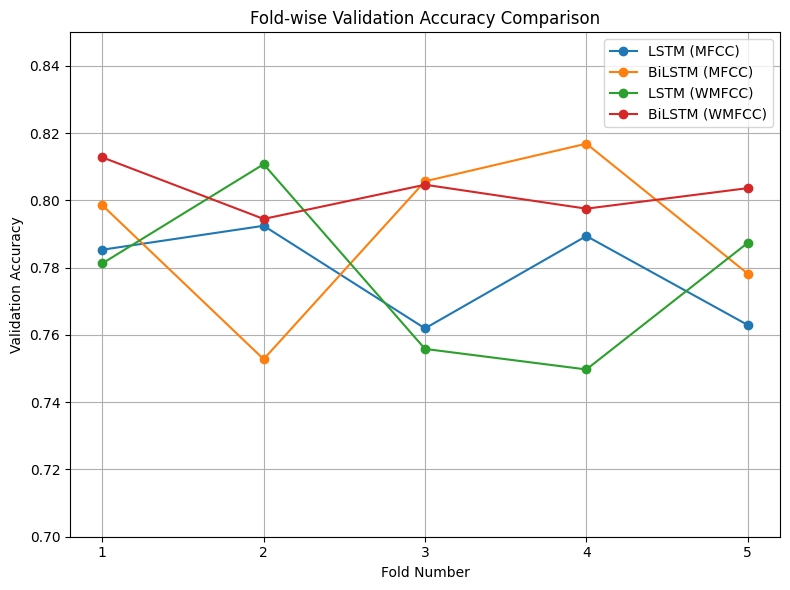

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

models_results = {
    "LSTM (MFCC)": results['LSTM'],
    "BiLSTM (MFCC)": results['BiLSTM'],
    "LSTM (WMFCC)": results['LSTM-WMFCC'],
    "BiLSTM (WMFCC)": results['BiLSTM-WMFCC']
}

for model_name, res in models_results.items():
    folds = np.arange(1, len(res['fold_accuracies']) + 1)
    plt.plot(folds, res['fold_accuracies'], marker='o', label=model_name)

plt.xlabel("Fold Number")
plt.ylabel("Validation Accuracy")
plt.title("Fold-wise Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.xticks(folds)
plt.ylim(0.7, 0.85)  # Set a moderate y-axis range
plt.tight_layout()
plt.show()

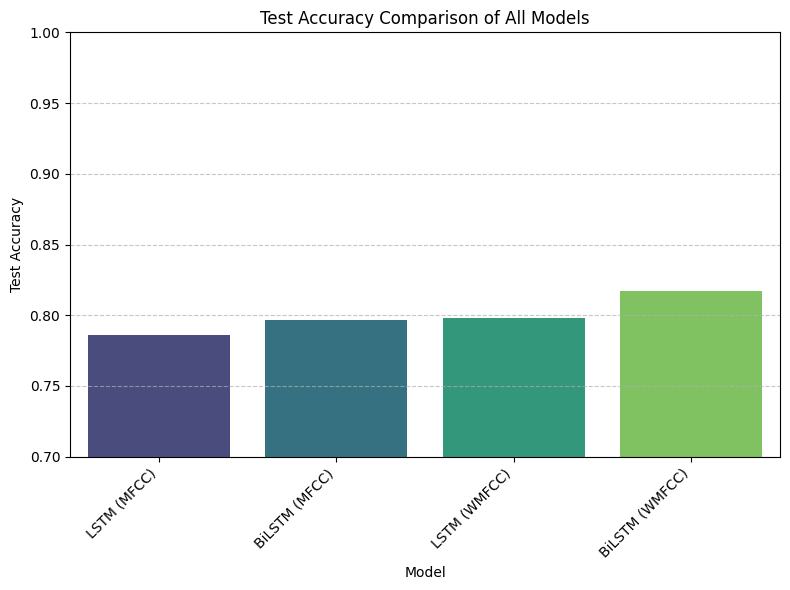

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract test accuracies for each model
model_names = [
    "LSTM (MFCC)",
    "BiLSTM (MFCC)",
    "LSTM (WMFCC)",
    "BiLSTM (WMFCC)"
]

accuracies = [
    results['LSTM']['test_accuracy'],
    results['BiLSTM']['test_accuracy'],
    results['LSTM-WMFCC']['test_accuracy'],
    results['BiLSTM-WMFCC']['test_accuracy']
]

# Create a DataFrame for easier plotting
accuracy_df = pd.DataFrame({
    'Model': model_names,
    'Test Accuracy': accuracies
})

# Plotting the bar graph
plt.figure(figsize=(8, 6))
sns.barplot(x='Model', y='Test Accuracy', data=accuracy_df, palette='viridis')
plt.ylim(0.7, 1.0) # Set y-axis limits to focus on accuracy range
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Comparison of All Models")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

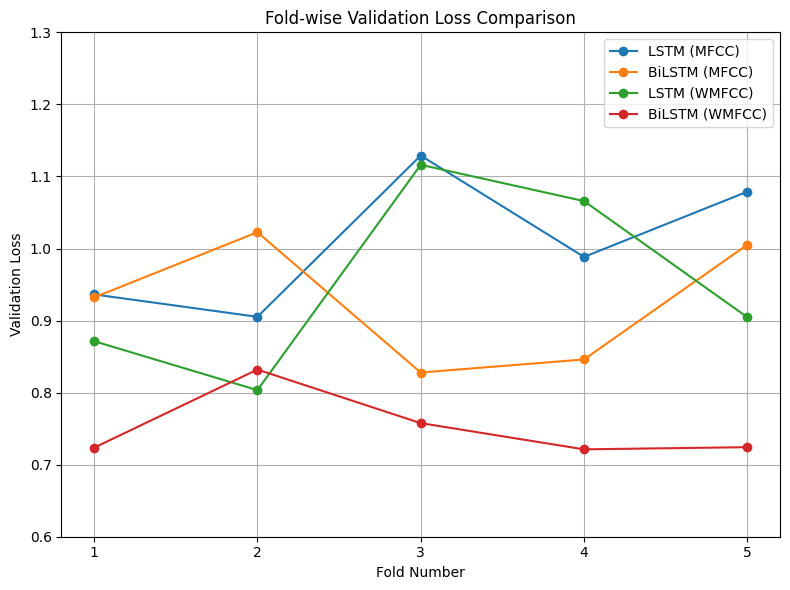

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

models_results = {
    "LSTM (MFCC)": results['LSTM'],
    "BiLSTM (MFCC)": results['BiLSTM'],
    "LSTM (WMFCC)": results['LSTM-WMFCC'],
    "BiLSTM (WMFCC)": results['BiLSTM-WMFCC']
}

for model_name, res in models_results.items():
    folds = np.arange(1, len(res['fold_losses']) + 1)
    plt.plot(folds, res['fold_losses'], marker='o', label=model_name)

plt.xlabel("Fold Number")
plt.ylabel("Validation Loss")
plt.title("Fold-wise Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.xticks(folds)
plt.ylim(0.6, 1.3) # Set a moderate y-axis range for loss
plt.tight_layout()
plt.show()